#Hausaufgabe 1 - Einführung in Python (100 Punkte)
> **Abgabe bis 16.11, 23:59**


Namen: [Marta Berdnik, Theodor Neroda]

## Aufgabe 0 - Funktioniert alles? (0 Punkte) 

Diese Aufgabe soll lediglich sicherstellen, dass euer Setup funktioniert und euch etwas Appetit machen auf das was kommt. ;)
Falls ihr Probleme habt, wendet euch an eure Tutor*innen.

Was zu tun ist:
- Führt den folgenden Code aus, indem ihr die Zelle auswählt und `Shift + Enter` drückt.
- Gebt eure Matrikelnummer in das Textfeld, welches am oberen Rand von VS Code erscheint, ein.
- Wählt ein Farbschema eurer Wahl, indem ihr eine Zahl von 1 bis 9 eingebt.
- Das Programm macht den Rest. :)




[1] Pastell 1   [2] Pastell 2   [3] Grautöne
[4] Rottöne     [5] Grüntöne    [6] Blautöne
[7] Orange      [8] Kupfer      [9] Ocean


Bild-Code für die Matrikelnummer 544288 erstellt als '544288.png'.


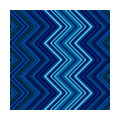

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import random
import math
import hashlib

img_size = 1024

def get_input():
   student_id = input("Bitte geben Sie ihre Matrikelnummer ein: ")
   if not student_id.isdigit():
      print("Dies ist keine gültige Matrikelnummer. Matrikelnummern sind immer Zahlen.")
      exit()
   else:
      print("\n")

   color_schemes = ["Pastel1", "Pastel2", "Greys", "Reds", "Greens", "Blues", "Oranges", "copper", "ocean"]
   print("[1] Pastell 1   [2] Pastell 2   [3] Grautöne")
   print("[4] Rottöne     [5] Grüntöne    [6] Blautöne")
   print("[7] Orange      [8] Kupfer      [9] Ocean")
   print("")
   selection = input("Wählen sie ein Farbschema: ")

   while not selection.isdigit() or int(selection) > 9 or int(selection) < 0:
      print("Bitte eine gültige Zahl (1-9) eingeben.")
      selection = input()

   color_scheme = color_schemes[int(selection)-1]

   return student_id, color_scheme

# Create a unique pixel pattern row based on student id through repeated hashing
def get_unique_pixel_pattern(student_id, img_width):
   sha256 = hashlib.sha512(student_id.encode()).hexdigest()
   retval = sha256

   while len(retval) < img_width:
      next_hash = hashlib.sha512(retval.encode()).hexdigest()
      retval += next_hash

   half_line = np.array([int(retval[i:i+2], 16) for i in range(0, img_width, 2)])

   return np.concatenate((half_line, half_line[::-1]), axis=0)

# Create a pattern by shifting parts of the image back and forth
def wiggle_img(img, pattern_repetitions):
   rows, column_indices = np.ogrid[:img.shape[0], :img.shape[1]]

   part_size = math.floor(img_size / pattern_repetitions)
   pos = True
   retval =  np.array([], dtype=int)

   for _ in range(pattern_repetitions):
      new = np.arange(part_size)[::int(pos) * 2 - 1]
      retval =  np.concatenate([retval, new])
      pos = not pos

   missing = img_size - retval.shape[0]
   final = np.arange(part_size)[::int(pos) * 2 - 1][:missing]

   r = np.concatenate([retval, final])

   r[r < 0] += img.shape[1]
   column_indices = column_indices - r[:, np.newaxis]

   return img[rows, column_indices]

# Input and setup
student_id, color_theme = get_input()
pixel_pattern = get_unique_pixel_pattern(student_id, img_size)
random.seed(student_id)
pattern_repetitions = random.randrange(2, 10)

# Generate image
img = np.tile(pixel_pattern, (img_size, 1))
img = wiggle_img(img, pattern_repetitions)
img = gaussian_filter(img, sigma=5)

# Plot and save image
fig = plt.figure(frameon=False)
fig.set_size_inches(1,1)
ax = plt.Axes(fig, [0., 0., 1., 1.])
ax.set_axis_off()
fig.add_axes(ax)
plt.imshow(img, cmap=color_theme, aspect="auto")
plt.savefig(f"{student_id}.png", dpi=1024)

print(f"\nBild-Code für die Matrikelnummer {student_id} erstellt als '{student_id}.png'.")

## Aufgabe 1 - Klausurzulassung-Rechner (30 Punkte)

Ergänzt die unten gegebene Funktion zur Berechnung des Zulassungskriteriums der Klausur und der Bonuspunkte. Dafür steht die Funktion ``compute_exam_eligibility()`` bereit. Diese kann um die benötigte Funktion ergänzt werden. Die vorgefertigte Funktion erwartet eine Liste mit allen 5 erreichten Hausaufgabenpunkten als Eingabewert. Diese könnte zum Beispiel so aussehen:

``homework_points_achieved = [100, 100, 75, 100, 80]``

Diese Liste wird an die Funktion ``compute_exam_eligibility()`` übergeben. Wenn der Code ausgeführt wird, sollte die Funktion schließlich die Klausurzulassung und das Gesamtergebnis (in Prozent) als Rückgabewert liefern und außerdem folgendes ausgeben:

```
Klausurzulassung: True
Ergebnis: 91/100 (91%)
```
(oder je nach Parameter eine andere Ausgabe)

<hr/>

**Hinweise:**
- Dieses Semester wird es insgesamt 5 Hausaufgaben geben mit insgesamt 500 Punkten.
- Diese 500 Punkte werden auf 100 Prozentpunkte skaliert. Das heißt, dass 500 Punkte 100 Prozentpunkten entsprechen, 250 Punkte 50 Prozentpunkten entsprechen, 0 Punkte 0 Prozentpunkten entsprechen, usw.
- Rundet das Ergebnis auf eine ganze Zahl (kaufpersonisches runden, das heißt, ab ``0.5`` wird aufgerundet!)
- Um zu der Klausur zugelassen zu werden, müsst ihr mindestens 50 % der Punkte erreichen. 
- Außerdem müsst ihr in jedem Hausaufgabenblatt mindestens 1/5 der Punkte erreichen.

In [4]:
def compute_exam_eligibility(achieved_points):
    ### Ändert hier nichts ###
    MAX_POINTS = 500
    score = 0
    exam_criteria = False

    # Hier testen wir, ob tatsächlich nur Zahlen in der übergebenen Liste sind und summieren diese auf
    # Falls nicht, kommen wir in den except-Block und die Funktion wird beendet
    try:
        point_sum = sum(achieved_points)
    except:
        raise(BaseException("Der Input ist nicht korrekt!"))
    ### ----------------- ###
    ### Hier euren Code einfügen ###
    
    # TODO:
    # - score auf 100 skalieren. z.B: 0 => 0, 500 => 100, 250 => 50
    #scs for decimals
    scaled_score = (point_sum / MAX_POINTS) * 100
    # - Punkte müssen Integer sein, also ggf. runden 
    score = int(round(scaled_score))
    # - Entscheiden, ob die errechneten Punkte für Kriterium 1 reichen
    #at least 50% achieved
    overall_score = score >= 50
    # - Entscheiden, ob die errechneten Punkte für Kriterium 2 reichen
    #all to only be true if every single item meets the condition, ps arbitrary
    sheet_score = all(ps >= 20 for ps in achieved_points)
    # - Falls beide Kriterien bestanden sind, Variable auf True setzen
    if overall_score and sheet_score:
        exam_criteria = True

    ### ----------------- ###
    # print results
    print(f"Klausurzulassung: {exam_criteria}")
    print(f"Ergebnis: {score}/100 ({score}%)")

    return (exam_criteria, score)

In [3]:
# Hiermit könnt ihr eure Funktion testen
# Hier sollte Klausurzulassung: False und erreichte Punkte in %: 36 ausgegeben werden
#inside the function list is taken, points get labeled as achieved_points 
points = [80, 100, 0, 0, 0]
results = compute_exam_eligibility(points)
assert results == (False, 36)

### Hier könnt ihr (freiwillig) weitere Tests in diesem Muster schreiben
points = [70, 99, 93, 72, 44]
results = compute_exam_eligibility(points)

Klausurzulassung: False
Ergebnis: 36/100 (36%)
Klausurzulassung: True
Ergebnis: 76/100 (76%)


## Aufgabe 2 - Eine heikle Angelegenheit (70 Punkte)

> ###*Die Zeit tickt davon! Ihr müsst schnell das Codewort erraten, welches die Bombe entschärft!*

In dieser Aufgabe sollt ihr ein Spiel implementieren, bei welchem aus einer Liste von Wörtern ein zufälliges ausgewählt wird und die SpielerIn das Wort erraten muss. Dies passiert durch Eingabe einzelner Buchstaben. Dabei hat die SpielerIn nur eine bestimmte Anzahl an Versuchen, um das Wort zu erraten. Insgesamt ähnelt das Spiel dem Spiel "Galgemännchen".

In [ ]:
### Ändert hier nichts - ihr dürft keine weiteren imports hinzufügen ###
import random
import matplotlib.pyplot as plt
import numpy as np

### 2.1 - Implementierung der Funktion ``choose_random_word()`` (5 Punkte)

Erstellt die Funktion ``choose_random_word()``, welche ein zufälliges Wort aus einer Liste zurückgibt. Diese Liste müsst ihr euch **nicht** ausdenken, da sie später vorgeben sein wird. Ihr könnt die Python Bibliothek ``random`` verwenden, um ein zufälliges Wort aus der Liste auszuwählen.

In [15]:
import random
# mit Hilfe dieser Testworte könnt ihr eure Funktion testen, allerdings wird diese Liste später in main() ersetzt.
words = ["Hier", "sind", "Testworte"] 

### ----------------- ###
### Hier euren Code einfügen ###
def choose_random_word(word_list):
    return random.choice(word_list)

#test
result = choose_random_word(words)
print(result)
# - Erstellt eine Funktion namens 'choose_random_word'
# - Diese soll eine Liste an Wörtern als Input bekommen
# - und ein zufälliges Wort aus dieser Liste zurückgeben

Testworte


### 2.2 - Implementierung der Funktion ``get_player_input()`` (15 Punkte)

Die Funktion ``get_player_input()`` soll den/die SpielerIn nach einem Buchstaben fragen und etwaige Fehler bei der Eingabe abfangen. Als Eingabewert bekommt die Funktion eine Liste mit bereits gespielten Buchstaben und dem zu erratenden Wort. Die Funktion soll den eingegebenen Buchstaben zur übergebenen Liste hinzufügen und beides zurückgeben.

**Hinweise:**
- Der/die SpielerIn soll nur *einen* Buchstaben eingeben können und keine bereits gespielten Buchstaben.
- Wenn der/die SpielerIn einen fehlerhaften Input eingibt, soll darauf hingewiesen werden mittels ``print`` und der/die SpielerIn soll erneut nach einem Buchstaben gefragt werden (dies kann rekursiv gelöst werden).
- Die Groß- und Kleinschreibung sollte bei der Eingabe keine Rolle spielen. Hier kann euch die Funktion ``lower()`` helfen. Die Worte, welche später zu erraten sind, können allerdings mit einem Großbuchstaben beginnen.


In [4]:
def get_player_input(played_letters):
    ### ----------------- ###
    ### Hier euren Code einfügen ###
    # TODO:
    # - Fordert die spielende Person auf, einen Buchstaben einzugeben
    #lower() turns whatever unput into lowercase
    while True:
        print("Geben Sie einen Buchstaben ein:")
        input_letter = input()
        input_letter = input_letter.lower()
    # - Prüft, ob der Input genau ein Buchstabe ist
    #len = length, not equal to 1
        if len(input_letter) != 1:
            print("Bitte geben Sie einen einzelnen Buchstaben ein.")
    # - Prüft, ob der Buchstabe bereits gespielt wurde. Beachtet dabei, dass Groß- und Kleinschreibung egal sein sollte!
        elif input_letter in played_letters:
            print("Diesen Buchstaben haben Sie bereits erraten. Wählen Sie erneut.")
    # - Falls ein Fehler bei der Eingabe auftritt, fordert die spielende Person erneut auf, 
    #   einen Buchstaben einzugeben (rekursiv) und weist mittels print() auf den Fehler hin
        elif input_letter not in 'abcdefghijklmnopqrstuvwxyzäöüß':
            print("Die Eingabe ist kein Teil des deutschen Alphabets.") 
    # - Updated die Liste der gespielten Buchstaben und gebt diese, sowie den eingegebenen Buchstaben zurück.
        else:
            played_letters.append(input_letter)
            return played_letters, input_letter

played_letters = []
get_player_input(played_letters)      



        

Geben Sie einen Buchstaben ein:


(['h'], 'h')

### 2.3 - Implementierung der Funktion ``plot_game()`` (30 Punkte)

Die Funktion ``plot_game()`` soll den aktuellen Spielstand visualisieren. Dafür soll die Funktion als Eingabewert das zu erratende Wort, die bereits gespielten Buchstaben und die Anzahl der Versuche bekommen. Die Funktion soll dann den aktuellen Spielstand visualisieren.

**Hinweise:**
- Das Beim Anzeigen des zu erratenden Wortes sollen nur die bereits erratenen Buchstaben angezeigt werden. Alle anderen Buchstaben sollen durch ``_ ``  (Unterstrich und Leerzeichen) ersetzt werden, f.e. Test bei geratenem t -> ``T _ _ t ``. Bei diesem Beispiel wurde bspw. "t" geraten und sowohl das große "T" als auch das kleine "t" im Wort ersetzt.
- Die Anzahl der Versuche soll ebenfalls angezeigt werden.
- Die Funktion hat keine Rückgabewerte, sondern soll den Spielstand visualisieren.
- Ihr könnt euch bei dem Plot gestalterisch austoben, allerdings müsst ihr einen Kreis zeichnen, der die Bombe darstellt und ein Element beinhalten, welches sich bei jedem falschen Versuch verändert. Dies kann z.B. eine Zündschnur sein, die sich verkürzt.

Dies könnte so aussehen:
<p>
  <img src="./falsch_geraten.png" alt="Falsch geraten!" width="300"/>
  <img src="./startposition.png" alt="Startposition" width="300"/>
</p>

Fehlerhafte Versuche:  5
Bereits gespielte Buchstaben:  ['a', 'b', 'c']
--------------
Wort: _ _ _ _ --------------


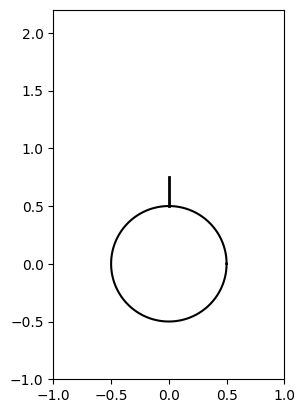

In [32]:
def plot_game(word, played_letters, wrong_attempts):
    # Hier werden die Anzahl der falschen Versuche und die bereits gespielten Buchstaben ausgegeben
    print("Fehlerhafte Versuche: ", wrong_attempts)
    print("Bereits gespielte Buchstaben: ", played_letters)
    print("--------------")
    if played_letters == []:
        print("Wort: ", "_ " * len(word))
    else:
        ### ----------------- ###
        ### Hier euren Code einfügen ###
        # TODO: Hier soll das Wort visualisiert werden, wobei bereits erratene Buchstaben angezeigt werden (Buchstabe und Leerzeichen)
        # und noch nicht erratene Buchstaben durch "_ " (Unterstrich und Leerzeichen) ersetzt werden
        print("Wort: ", end="")
        for character in word:
            if character.lower() in played_letters:
                print(character + " ", end="")
            else:
                print("_ ", end="")
                  
        ### ----------------- ###

    print("--------------")

    ### ----------------- ###
    ### Hier euren Code einfügen ###
    # TODO:
    fig, ax = plt.subplots()

    theta = np.linspace(0, 2 * np.pi, 100)
    x_circle = 0.5 * np.cos(theta)
    y_circle = 0.5 * np.sin(theta)

    if wrong_attempts >= 6:
        ax.fill(x_circle, y_circle, color='red')
    else:
        ax.plot(x_circle, y_circle, color='black')

    start_y = 0.5          

    current_fuse_height = start_y + max(0, (6 - wrong_attempts) * 0.25)
    
    if wrong_attempts < 6:
        ax.plot([0, 0], [start_y, current_fuse_height], color='black', linewidth=2)

   
    ax.set_xlim(-1.0, 1.0)
    ax.set_ylim(-1.0, 2.2)
    ax.set_aspect('equal') # Wichtig, damit der Kreis rund bleibt!

    plt.show()
#test
plot_game(choose_random_word(words), played_letters = ['a', 'b', 'c'], wrong_attempts=5)

    # - Hier sollt ihr ein Bild mittels matplotlib erstellen, welches die Anzahl der falschen Versuche visualisiert
    # - In dem Bild soll eine Bombe gezeichnet werden (ein Kreis) und eine kürzer werdende Zündschnur, je mehr falsche Versuche gemacht wurden
    # - falls der 6. falsche Versuch gemacht wurde, soll die Bombe explodieren (z.B. durch Füllen des Kreises mit einer anderen Farbe)
    # - Hinweise: 
    #   - Überlegt euch wie ihr einen Kreis zeichnen könnt (Tipp: nutzt np.cos(), np.sin() und np.linspace()) -> ihr dürft NICHT plt.Circle() verwenden
    #   - Ihr könnt die Achsenlänge des Plots mit ax.set_xlim() und ax.set_ylim() festlegen, sodass der Kreis nicht verzerrt wird

### 2.4 - Implementierung der Funktion ``main()`` (20 Punkte)

Die Funktion ``main()`` soll die oben genannten Funktionen zusammenführen und das Spiel starten. Die Funktion soll das Spiel starten und den/die SpielerIn nach jedem Versuch den aktuellen Spielstand mittels ``plot_game()`` anzeigen. Wenn der/die SpielerIn das Wort erraten hat, soll das Spiel beendet werden und eine entsprechende Nachricht ausgegeben werden. Wenn der/die SpielerIn das Wort nicht erraten hat, soll das Spiel beim 6. erfolglosen Versuch beendet werden und eine entsprechende Nachricht ausgegeben werden, welche das Wort enthüllt.

**Hinweise:**
- Die Funktion ``main()`` soll die Funktionen ``choose_random_word()``, ``get_player_input()`` und ``plot_game()`` verwenden
- ``main()`` soll das Spiel initialisieren
- Beachtet, dass die Groß- und Kleinschreibung keine Rolle spielen soll, allerdings soll das Wort am Ende in der korrekten Schreibweise angezeigt werden. Also wenn das Wort "Roboter" ist, soll am Ende ``R o b o t e r `` angezeigt werden und nicht ``r o b o t e r ``.

Fehlerhafte Versuche:  0
Bereits gespielte Buchstaben:  []
--------------
Wort:  _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 
--------------


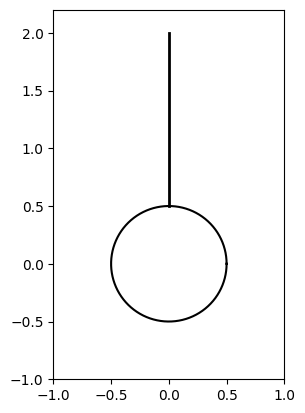

In [42]:
def main():
    words = ["Hallo", "Hausaufgabe", "Python", "Programmieren", "Kurs", "Semester", "Ferien", "Universität", "Informatik", "Berlin", "Technologie", "Computer", "Mensch", "Roboter", "Forschung", "Mathematik", "Psychologie", "Kreativität", "Bildung", "Wissenschaft", "Kunst", "Musik", "Geschichte", "Politik", "Philosophie", "Literatur", "Sprache", "Kultur", "Sport", "Gesundheit", "Ernährung", "Natur", "Umwelt", "Technik", "Wirtschaft", "Gesellschaft", "Zukunft", "Vergangenheit", "Gegenwart", "Leben", "Freundschaft" "Beziehung", "Kommunikation", "Kooperation", "Konflikt","Gerechtigkeit", "Demokratie", "Verantwortung", "Fiktion", "Realität", "Traum", "Wahrheit", "Lüge", "Geheimnis", "Abenteuer", "Reise", "Entdeckung", "Entwicklung", "Veränderung", "Bewegung", "Chaos", "Ordnung", "Struktur", "System", "Organisation", "Planung",  "Methode", "Werkzeug", "Maschine", "Anwendung", "Funktion", "Entscheidung"]
    played_letters = []
    wrong_attempts = 0

    ### ----------------- ###
    ### Hier euren Code einfügen ###
    # TODO: 
    # - ruft choose_random_word() mit der words-Liste auf und speichert das Ergebnis in der Variable word
    choose_random_word(words)
    # - nutzt eure Funktionen plot_game() und get_player_input() um das Spiel zu starten
    plot_game(choose_random_word(words), played_letters = [], wrong_attempts=0)
    # - das Spiel soll so lange laufen, bis das Wort erraten wurde oder 6 falsche Versuche gemacht wurden
    
    # - plot_game() soll dabei nach jedem Zug aufgerufen werden um den aktuellen Spielstand zu visualisieren
    # - nach dem Spiel soll das Ergebnis ausgegeben mittels print() werden (gewonnen oder verloren)
    ### ----------------- ###
# Hier wird main aufgerufen, um das Spiel zu starten
main()